#### ClusterCentroids
With a Regression Target

##### Imports

In [8]:
# pip install imblearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler, ClusterCentroids
import warnings

warnings.filterwarnings("ignore")

# Loading the dataset
df = pd.read_csv("../../laptopprice_dataset_cleaned.csv")


df

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,0,1,0,0,0,1,0,1,0,0
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,0,1,0,0,0,1,0,1,0,0
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,0,1,0,0,0,1,0,0,1,0
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,0,1,0,1,0,0,1,0,0
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,0,1,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,4,2.20,10.555257,0,0,100.454670,500,0,0,0,...,0,0,1,0,0,0,1,0,0,1
1269,4,1.80,10.433899,1,1,157.350512,0,128,0,0,...,0,0,1,0,0,1,0,0,0,1
1270,16,1.30,11.288115,1,1,276.053530,0,512,0,0,...,0,0,1,0,0,1,0,0,0,1
1271,2,1.50,9.409283,0,0,111.935204,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1


In [9]:
# let's filter some extreme outliers on the high end
df.query("Price <= Price.quantile(0.99)", inplace=True)

<Axes: xlabel='target_binned', ylabel='Count'>

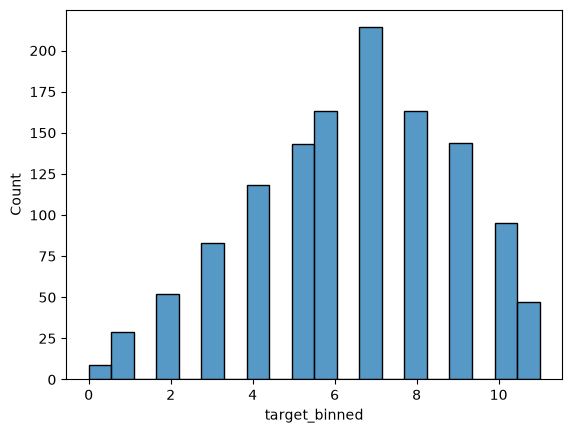

In [10]:
# Create 12 bins of Price. 
target = "Price"
df['target_binned'] = pd.cut(df[target], bins=12, labels=False)

# That looks like so.
sns.histplot(df, x="target_binned")

In [11]:
# This is really helpful to help you set the 'strategy' parameter in Undersampling.
# NOTE: This assumes your dataframe is called `df`

# Insert your column name here
column_name = "target_binned"

# Extract the unique values
column = df[column_name]
unique_values = column.unique()

# For each unique value, print the count.
for unique_value in unique_values:
    count = (column == unique_value).sum()
    print(unique_value,":", count)

# Now we know our upper limits when setting the strategy.

8 : 163
6 : 163
4 : 118
11 : 47
9 : 144
3 : 83
10 : 95
7 : 214
2 : 52
0 : 9
1 : 29
5 : 143


#### ClusterCentroids
This is typically used to preserve cluster relationships and tries to represent that structure with fewer points.

In [12]:
from imblearn.under_sampling import ClusterCentroids

# X, y split
X = df.drop('target_binned', axis=1)
y = df['target_binned']

# Set the strategy to tailor our needs. In this case
# Say we did some extensive research into this data
# and it's more realistic that all the diamonds have
# a normally distributed price. Let's make it look 
# that way instead.
strategy = {
    0 : 9,
    1 : 29,
    2 : 52,
    3 : 83,
    4 : 118,
    5 : 143,
    6 : 163,
    7 : 214,
    8 : 163,
    9 : 144,
    10 : 95,
    11 : 47
}


# Create the ClusterCentroids sampler
sampler = ClusterCentroids(sampling_strategy=strategy, random_state=321)

# Use the sampler
X_resampled, y_resampled = sampler.fit_resample(X, y)

# Put the dataframe back together after sampling
df_resampled_cc = pd.DataFrame(
    X_resampled,
    columns=X.columns
)

# Keep the binned target
df_resampled_cc['target_binned'] = y_resampled

<Axes: xlabel='target_binned', ylabel='Count'>

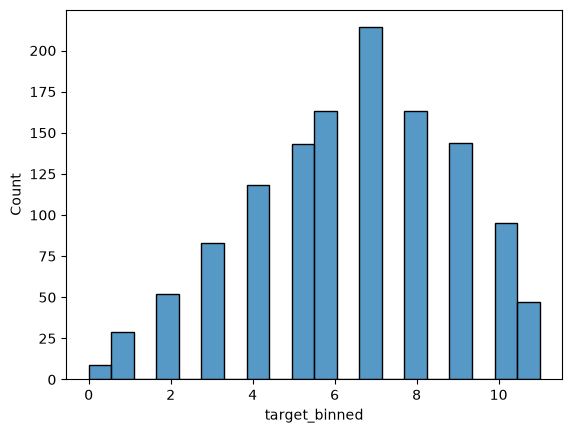

In [13]:
# see the binned target distribution
sns.histplot(df_resampled_cc, x="target_binned")

In [14]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [15]:
# Comparing the two statistically
df.describe()   

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,target_binned
count,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,...,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00
mean,8.25,2.03,10.81,0.15,0.28,146.48,414.81,180.59,0.08,0.02,...,0.34,0.40,0.11,0.14,0.56,0.30,0.02,0.12,0.86,6.44
std,4.53,0.65,0.60,0.35,0.45,42.35,518.49,176.34,0.27,0.13,...,0.47,0.49,0.31,0.35,0.50,0.46,0.13,0.33,0.34,2.50
min,2.00,0.69,9.13,0.00,0.00,90.58,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.50,10.37,0.00,0.00,127.34,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,5.00
50%,8.00,2.04,10.86,0.00,0.00,141.21,0.00,256.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,7.00
75%,8.00,2.30,11.27,0.00,1.00,157.35,1000.00,256.00,0.00,0.00,...,1.00,1.00,0.00,0.00,1.00,1.00,0.00,0.00,1.00,8.00
max,32.00,4.60,12.03,1.00,1.00,352.47,2000.00,1024.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,11.00


In [16]:
# the results are surprisingly close
# naturally price changed a bit since we had to bin it
df_resampled_cc.describe()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,target_binned
count,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,...,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00
mean,8.25,2.03,10.81,0.15,0.28,146.48,414.81,180.59,0.08,0.02,...,0.34,0.40,0.11,0.14,0.56,0.30,0.02,0.12,0.86,6.44
std,4.53,0.65,0.60,0.35,0.45,42.35,518.49,176.34,0.27,0.13,...,0.47,0.49,0.31,0.35,0.50,0.46,0.13,0.33,0.34,2.50
min,2.00,0.69,9.13,0.00,0.00,90.58,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.50,10.37,0.00,0.00,127.34,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,5.00
50%,8.00,2.04,10.86,0.00,0.00,141.21,0.00,256.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,7.00
75%,8.00,2.30,11.27,0.00,1.00,157.35,1000.00,256.00,0.00,0.00,...,1.00,1.00,0.00,0.00,1.00,1.00,0.00,0.00,1.00,8.00
max,32.00,4.60,12.03,1.00,1.00,352.47,2000.00,1024.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,11.00


In [17]:
# remember to check out the variances too!
df.var()

Ram                                   20.51
Weight                                 0.42
Price                                  0.37
TouchScreen                            0.13
Ips                                    0.20
Ppi                                 1793.57
HDD                               268834.84
SSD                                31094.59
Company_Acer                           0.07
Company_Apple                          0.02
Company_Asus                           0.10
Company_Chuwi                          0.00
Company_Dell                           0.18
Company_Fujitsu                        0.00
Company_Google                         0.00
Company_HP                             0.17
Company_Huawei                         0.00
Company_LG                             0.00
Company_Lenovo                         0.18
Company_MSI                            0.04
Company_Mediacom                       0.01
Company_Microsoft                      0.00
Company_Razer                   

In [18]:
# some changes happened, but they are in the same ball park!
df_resampled_cc.var()

Ram                                   20.51
Weight                                 0.42
Price                                  0.37
TouchScreen                            0.13
Ips                                    0.20
Ppi                                 1793.57
HDD                               268834.84
SSD                                31094.59
Company_Acer                           0.07
Company_Apple                          0.02
Company_Asus                           0.10
Company_Chuwi                          0.00
Company_Dell                           0.18
Company_Fujitsu                        0.00
Company_Google                         0.00
Company_HP                             0.17
Company_Huawei                         0.00
Company_LG                             0.00
Company_Lenovo                         0.18
Company_MSI                            0.04
Company_Mediacom                       0.01
Company_Microsoft                      0.00
Company_Razer                   